# 6. Allyl Cation: &pi; Orbitals

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4/blob/main/book/06-PiOrbitals/061-PiOrbitals.ipynb)
:::

Simplified **Hückel Molecular Orbital Theory** (SHMO) allows us to create &pi;-molecular orbitals for planar systems. It is **qualitatively** accurate and often all one needs to interpret &pi;-systems in physical organic chemistry. We have explored SHMO and created **MO diagrams** for ethylene, allyl anion & cation, butadiene and the cumyl cation. We have modeled the phenol and the nitrobenzene system as well. And we explored the surprising polar nature of azulene compared to naphthalene. We did all this with *Python* and the *NumPy* \& *SciPy* packages.

Can we do the same, only better, with *Psi4*? Let's get busy.

## Learning Goals

In this exercise, we will accomplish the following…

1.	**Build** a charged molecule for *Psi4* with *Python*, using the **symmetry** of the molecule to place the atoms, and run the calculations from a *Jupyter* notebook.
2.	Use *py3Dmol* (and *Avogadro*) to generate graphical **images** of the molecule and surfaces that represent electron density and molecular and local orbitals.
3.	Use the colour-coded **electrostatic potential energy surface** to interpret the polarity of the molecules.
4.	Use the information in the results to determine the **charge** on each atom and compare these to SHMO results.
5.	Create a detailed **MO diagram** for the molecules described above and include relevant **images** of the molecular orbitals.

In [45]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot style sheets from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/S2_classic2.mplstyle

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    plt.style.use("../../styles/tufte.mplstyle")

## Setting Up the Notebook

As always, the first code cell of the notebook (hidden on this web page) **imports** *Psi4*, *py3Dmol*, *NumPy*, *pandas* and *Matplotlib* and applies the plot **style sheet**. See [Chapter 2](../02-SmallMolecules/021-SmallMolecules.ipynb) for the details.

```{admonition} Running this notebook in Google Colab
:class: dropdown
The first code cell checks whether the notebook is running in *Google Colab*. If it is, the cell **installs** *Psi4* for you. *Colab* does not come with *conda*, so the cell first installs it using a package called *condacolab*. This **restarts** the *Colab* session. When it has restarted, simply **run the first cell again**. It will then install *Psi4* with *conda* (*Psi4* cannot be installed with *pip*), install *py3Dmol* with *pip*, and download the plot style sheets from the book's *GitHub* repository. This takes a few minutes, and you must do it every time you start a new *Colab* session. On your own computer, the cell just imports the packages.
```

Next, we tell *Psi4* how much of the computer it may use and set a few options.

In [46]:
psi4.set_memory("4 GB")
psi4.set_num_threads(4)

psi4.set_options({"scf_type": "pk",
                  "puream": False,
                  "cubic_grid_spacing": [0.4, 0.4, 0.4],
                  "cubic_grid_overage": [5.0, 3.0, 3.0]})

| Line | Notes |
| :---- | :---- |
| `"puream": False` | Use **Cartesian** *d*-functions (six of them: *xx*, *yy*, *zz*, *xy*, *xz*, *yz*) rather than the five "pure" spherical *d*-functions. *Psi4* would normally use pure functions for the 6-311++G(d,p) basis set. *GAMESS* uses Cartesian functions by default, so this makes our calculation the **same** as the one in the *GAMESS* book, right down to the number of basis functions. |
| `cubic_grid_spacing`, `cubic_grid_overage` | The spacing of the grid points and the extra space around the molecule (in Bohr) for the **cube files** of orbitals, density and electrostatic potential. We met these in [Chapter 3](../03-VisualInput/031-VisualInput.ipynb). |
| `[5.0, 3.0, 3.0]` | The extra space is given separately for *x*, *y* and *z*. Our allyl cation is **flat** and lies in the *yz* plane, so with only 3 Bohr of space above and below the plane the box would be too thin and the top and bottom of the density surface and the &pi;-orbitals would be **cut off**. We give it 5 Bohr in the *x* direction. |

### Some Helpful Tools

We will reuse our **tools** from the previous chapters and add one more. The cell is hidden on the web page but you can expand it to see the code.

In [47]:
def show_molecule(mol):
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def bond_length(mol, i, j):
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms
    return np.linalg.norm(xyz[i] - xyz[j])

def bond_angle(mol, i, j, k):
    xyz = mol.geometry().np
    a = xyz[i] - xyz[j]
    b = xyz[k] - xyz[j]
    cos_angle = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(cos_angle))

def plot_history(history, title):
    energies = np.array(history["energy"])
    delta_E = (energies - energies[-1]) * psi4.constants.hartree2kJmol
    steps = np.arange(1, len(energies) + 1)

    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
    ax.plot(steps, delta_E, color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
    ax.set_xticks(steps)
    ax.set_xlabel("Optimization step")
    ax.set_ylabel(r"$E - E_{final}$ (kJ/mol)")
    ax.set_title(title)
    plt.show()

def search_file(filename, text):
    with open(filename) as f:
        for number, line in enumerate(f, start=1):
            if text.lower() in line.lower():
                print(f"{number:6d}: {line.rstrip()}")

def show_orbital(mol, cube_file, isoval=0.05):
    with open(cube_file) as f:
        cube = f.read()
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.addVolumetricData(cube, "cube", {"isoval": isoval, "color": "#FFB3BA", "opacity": 0.85})
    view.addVolumetricData(cube, "cube", {"isoval": -isoval, "color": "#AEC6CF", "opacity": 0.85})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def show_density_esp(mol, density_file, esp_file, esp_min, esp_max, isoval=0.002):
    with open(density_file) as f:
        density = f.read()
    with open(esp_file) as f:
        esp = f.read()
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.addVolumetricData(density, "cube", {"isoval": isoval, "opacity": 0.9,
                                             "voldata": esp, "volformat": "cube",
                                             "volscheme": {"gradient": "rwb",
                                                           "min": esp_min, "max": esp_max}})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def cube_values(cube_file):
    with open(cube_file) as f:
        lines = f.readlines()
    n_atoms = abs(int(lines[2].split()[0]))
    numbers = " ".join(lines[6 + n_atoms:]).split()
    return np.array(numbers, dtype=float)

| Function | What it does |
| :---- | :---- |
| `show_molecule(mol)` | Draws the molecule with *py3Dmol*. |
| `bond_length(mol, i, j)` | Distance between atoms `i` and `j` in &Aring;. |
| `bond_angle(mol, i, j, k)` | Angle `i`&ndash;`j`&ndash;`k` in degrees, with `j` the central atom. |
| `plot_history(history, title)` | Plots the energy at each step of an optimization relative to the final energy. |
| `search_file(filename, text)` | Prints every line of a file that contains `text`. |
| `show_orbital(mol, cube_file)` | Draws an orbital from a cube file, pink for the positive phase and blue for the negative phase. |
| `show_density_esp(...)` | Draws the electron density surface coloured by the electrostatic potential. This time we give it the **lowest** and **highest** values (`esp_min`, `esp_max`) for the colour scale, red at the low end and blue at the high end. Our molecule is a **cation** so the potential is positive everywhere and the old symmetric scale would be all blue. |
| `cube_values(cube_file)` | **New.** Reads all the numbers in a cube file into a *NumPy* array. A cube file has two title lines, a line with the number of atoms, three lines describing the grid and one line for each atom. Everything after that is the **data**, one value for each grid point. We will use it to find the range of the electrostatic potential on the density surface. |

## The Allyl System

For an example we will build the **allyl cation** and examine the results of the calculation. The allyl cation is **planar** and has a *C<sub>2</sub>* axis through the central C&ndash;H bond, a mirror plane containing all the atoms and a second mirror plane perpendicular to it. It belongs to the *C<sub>2v</sub>* point group, just like water.

In the *GAMESS* book, I built the cation with symmetry in *MacMolPlt*. I set the point group to *C<sub>2v</sub>* and placed only the **symmetry-unique** atoms (two carbons and three hydrogens). The program generated the others. After that, it was up to **trial and error**. *Psi4* wants **all** the atoms, and it detects the symmetry by itself (see [Chapter 2](../02-SmallMolecules/021-SmallMolecules.ipynb)). So I took the five unique atoms from my *GAMESS* input file and **generated** the other three by hand. The *z*-axis is the *C<sub>2</sub>* axis and the molecule lies in the *yz* plane. A reflection through the *xz* plane changes *y* to &minus;*y*, so each atom that is not on the *z*-axis gets a **twin** with the sign of *y* flipped.

| Atom | Role | x | y | z |
| :---- | :---- | :---: | :---: | :---: |
| C1 | terminal carbon | 0 | 1.05078 | 0 |
| C2 | twin of C1 | 0 | &minus;1.05078 | 0 |
| C3 | central carbon | 0 | 0 | 1.10972 |
| H4 | on C3 | 0 | 0 | 2.24972 |
| H5, H6 | on C1 and C2 | 0 | &plusmn;2.15957 | 0.26491 |
| H7, H8 | on C1 and C2 | 0 | &plusmn;0.72580 | &minus;1.09270 |

I listed the atoms in the **same order** that *GAMESS* used in its output, so that our atom numbers match those in the previous book. This is a rough starting structure (the C&ndash;C bonds are 1.53 &Aring; long). The optimization will fix it.

```{tip}
*Avogadro* can also help you with symmetry. Build a rough allyl cation, then look for its symmetry tools to detect the point group and **symmetrize** the structure, and save the result as an *xyz* file as we did in [Chapter 3](../03-VisualInput/031-VisualInput.ipynb).
```

In [48]:
allyl = psi4.geometry("""
1 1
C    0.00000    1.05078    0.00000
C    0.00000   -1.05078    0.00000
C    0.00000    0.00000    1.10972
H    0.00000    0.00000    2.24972
H    0.00000    2.15957    0.26491
H    0.00000   -2.15957    0.26491
H    0.00000    0.72580   -1.09270
H    0.00000   -0.72580   -1.09270
no_reorient
""")

allyl.update_geometry()
print("Full point group:         ", allyl.get_full_point_group())
print("Computational point group:", allyl.schoenflies_symbol())
show_molecule(allyl)

Full point group:          C2v
Computational point group: c2v


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `1 1` | The **charge** is +1 (a cation) and the **multiplicity** is 1 (a singlet, all electrons paired). Get this wrong and you will be calculating the allyl **radical** or something even stranger. |
| `no_reorient` | Keeps the molecule in **our** orientation, in the *yz* plane, as it was in *GAMESS*. That way the &pi;-orbitals are built from the *p<sub>x</sub>* atomic orbitals, the same as in the previous book. *Psi4* still moves the center of mass to the origin. |

*Psi4* found the *C<sub>2v</sub>* point group and can use all of it for the calculation.

### Optimizing the Structure

In the *GAMESS* book I used the 6-311G basis set with *d* and *p* polarization functions and both diffuse functions. In *Psi4* that is simply `6-311++g(d,p)`. The **diffuse functions** (the `++`) are important as they improve results for **charged** systems. The extra electron density (or the lack of it) needs room to spread out.

Optimizer: Optimization complete!
Final energy: -116.22164803 Hartree
Steps taken: 8


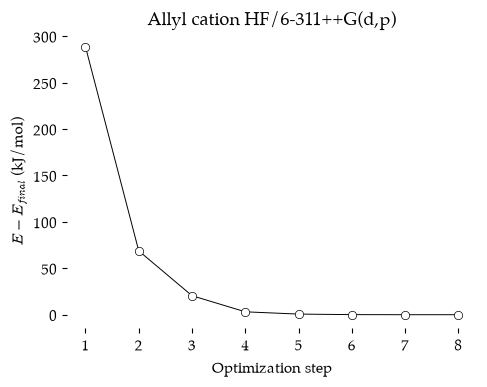

In [49]:
psi4.set_output_file("allyl_opt.out", False)

E_opt, hist_opt = psi4.optimize("hf/6-311++g(d,p)", molecule=allyl, return_history=True)

print(f"Final energy: {E_opt:.8f} Hartree")
print("Steps taken:", len(hist_opt["energy"]))
plot_history(hist_opt, "Allyl cation HF/6-311++G(d,p)")

| Line | Notes |
| :---- | :---- |
| `"hf/6-311++g(d,p)"` | Restricted Hartree-Fock with the 6-311++G(d,p) basis set. This is the same as `GBASIS=N311 NGAUSS=6 NDFUNC=1 NPFUNC=1 DIFFSP=.TRUE. DIFFS=.TRUE.` in *GAMESS*: one set of *d*-functions on carbon, one set of *p*-functions on hydrogen, a diffuse *sp* shell on carbon and a diffuse *s* shell on hydrogen. |

The optimization reached &minus;116.22164803 Hartree in **8** steps. The plot shows the usual steep drop as our rough starting structure relaxes. The *GAMESS* job used a convergence test on the gradient alone (`OPTTOL=0.0001` Hartree/Bohr for the largest component). *Psi4*'s default criteria also check the change in energy and the size of the step (see [Chapter 2](../02-SmallMolecules/021-SmallMolecules.ipynb)), so the two programs do not stop at exactly the same place. They are close enough for us.

In [50]:
print(f"C1-C3 length:   {bond_length(allyl, 0, 2):.4f} Angstrom")
print(f"C3-H4 length:   {bond_length(allyl, 2, 3):.4f} Angstrom")
print(f"C1-H5 length:   {bond_length(allyl, 0, 4):.4f} Angstrom")
print(f"C1-H7 length:   {bond_length(allyl, 0, 6):.4f} Angstrom")
print(f"C1-C3-C2 angle: {bond_angle(allyl, 0, 2, 1):.2f} degrees")
print(f"H5-C1-H7 angle: {bond_angle(allyl, 4, 0, 6):.2f} degrees")

show_molecule(allyl)

C1-C3 length:   1.3725 Angstrom
C3-H4 length:   1.0739 Angstrom
C1-H5 length:   1.0775 Angstrom
C1-H7 length:   1.0777 Angstrom
C1-C3-C2 angle: 118.04 degrees
H5-C1-H7 angle: 116.98 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Remember that *Python* counts from **zero**: C1 is atom `0`, C3 is atom `2` and H4 is atom `3`.

Both C&ndash;C bonds are 1.3725 &Aring;, halfway between a single and a double bond, as we would expect for a delocalized &pi;-system. The structure is not a close match to the literature values. For example, the C&ndash;C&ndash;C bond angle is 118.04&deg; while the literature value is 124.6&deg;. It is **expected** that the angle should be greater than 120&deg; so I was suspicious of the result. (*GAMESS* got 118&deg; too, so at least the two programs agree on the wrong answer.) Ions are **tough**. More expensive methods will be needed but we can still obtain fairly decent descriptions of the orbitals and charge density. They won't be perfect, but will give us the general idea.

### Analysis of Charges

Now let us run a **single point** energy calculation on the optimized structure and keep the wavefunction. We will use it to look at the electron density and the charges.

We can obtain an **image** that represents the electron density of the molecule with the colours mapped onto the surface representing the **charge**. Red are regions that attract a positive charge and blue are regions that repel a positive charge. Well, in a cation **everything** repels a positive charge, so here red marks the **least positive** regions and blue the **most positive**. As in [Chapter 3](../03-VisualInput/031-VisualInput.ipynb), *Psi4* needs a density-fitted wavefunction to make the electrostatic potential cube file.

In [51]:
psi4.set_output_file("allyl_esp.out", False)
psi4.set_options({"scf_type": "df"})

E_df, wfn_df = psi4.energy("hf/6-311++g(d,p)", molecule=allyl, return_wfn=True)
print(f"Energy (density fitted): {E_df:.8f} Hartree")

Path("cube_esp").mkdir(exist_ok=True)
psi4.set_options({"cubeprop_tasks": ["density", "esp"],
                  "cubeprop_filepath": "cube_esp"})
psi4.cubeprop(wfn_df)
psi4.set_options({"scf_type": "pk"})

density = cube_values("cube_esp/Dt.cube")
esp = cube_values("cube_esp/ESP.cube")
on_surface = abs(density - 0.002) < 0.0002
print(f"ESP on the surface: {esp[on_surface].min():.4f} to {esp[on_surface].max():.4f} Hartree/e")

Energy (density fitted): -116.22163444 Hartree
ESP on the surface: 0.1873 to 0.2574 Hartree/e


| Line | Notes |
| :---- | :---- |
| `density = cube_values("cube_esp/Dt.cube")` | The total electron **density** at every grid point. |
| `esp = cube_values("cube_esp/ESP.cube")` | The electrostatic **potential** at the same grid points, in the same order. |
| `on_surface = abs(density - 0.002) < 0.0002` | A list of `True`/`False` values: `True` for the grid points where the density is close to 0.002 electrons per Bohr&sup3;. This is the density **surface** that we will draw. |
| `esp[on_surface].min()` | The **lowest** potential among those points. `.max()` gives the highest. |

The density-fitted energy (&minus;116.22163444 Hartree) is only 1.4 &times; 10<sup>&minus;5</sup> Hartree (0.04 *kJ/mol*) above the exact one. The potential on the surface runs from 0.187 to 0.257 Hartree per unit charge (about 490 to 680 *kJ/mol*). It is **positive everywhere**. That is what a cation looks like to an approaching positive charge. Let us use that range for our colour scale.

In [52]:
show_density_esp(allyl, "cube_esp/Dt.cube", "cube_esp/ESP.cube",
                 esp_min=esp[on_surface].min(), esp_max=esp[on_surface].max())

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Rotate the molecule. We can see that the positive charge is **located** on the two terminal carbon groups, as expected. The central C&ndash;H group is the least positive part of the cation.

```{margin}
Someday, I will explore using *Multiwfn*, a package for analyzing molecular wavefunction data produced by programs like *Psi4*. Perhaps you will be the pioneer. See more [here](http://sobereva.com/multiwfn/index.html).
```

We can get an **approximation** of the charge held by each group from the wavefunction. In *GAMESS* we searched the output file for the word "`LOWDIN`". In *Psi4* we ask for the charges with the `psi4.oeprop()` function (one-electron **properties**). We will calculate them at HF/6-311++G(d,p) now and again with B3LYP below.

In [53]:
psi4.set_output_file("allyl_hf.out", False)

E_hf, wfn_hf = psi4.energy("hf/6-311++g(d,p)", molecule=allyl, return_wfn=True)
print(f"Energy: {E_hf:.8f} Hartree")

psi4.oeprop(wfn_hf, "MULLIKEN_CHARGES", "LOWDIN_CHARGES")

atoms = ["C1", "C2", "C3", "H4", "H5", "H6", "H7", "H8"]
charges_hf = pd.DataFrame({"Atom": atoms,
                           "Mulliken": wfn_hf.variable("MULLIKEN CHARGES"),
                           "Lowdin": wfn_hf.variable("LOWDIN CHARGES")})
charges_hf.round(4)

Energy: -116.22164803 Hartree


,Atom,Mulliken,Lowdin
0,C1,-0.2067,0.2396
1,C2,-0.2067,0.2396
2,C3,0.1863,-0.1460
3,H4,0.2899,0.1321
4,H5,0.2393,0.1338
5,H6,0.2393,0.1338
6,H7,0.2293,0.1335
7,H8,0.2293,0.1335


| Line | Notes |
| :---- | :---- |
| `psi4.oeprop(wfn_hf, "MULLIKEN_CHARGES", "LOWDIN_CHARGES")` | Calculates the atomic **charges** from the wavefunction using two common methods: Mulliken and L&ouml;wdin. The results are printed in the output file and stored in the wavefunction. |
| `wfn_hf.variable("LOWDIN CHARGES")` | Gets the L&ouml;wdin charges back as an array, one value per atom, in the order of our geometry. |

Here is reported **calculations** of partial atomic charge according to two common methods: Mulliken and L&ouml;wdin. Both methods divide up the electrons among the atoms using the **basis functions** that "belong" to each atom, and both are rather arbitrary. We will use L&ouml;wdin. The same numbers are in the output file.

In [54]:
with open("allyl_hf.out") as f:
    lines = f.readlines()

start = next(i for i, line in enumerate(lines) if "Lowdin Charges" in line)
print("".join(lines[start:start + 12]))

  Lowdin Charges: (a.u.)
   Center  Symbol    Alpha    Beta     Spin     Total
       1     C     2.88018  2.88018  0.00000  0.23965
       2     C     2.88018  2.88018  0.00000  0.23965
       3     C     3.07301  3.07301  0.00000 -0.14601
       4     H     0.43397  0.43397  0.00000  0.13205
       5     H     0.43310  0.43310  0.00000  0.13379
       6     H     0.43310  0.43310  0.00000  0.13379
       7     H     0.43323  0.43323  0.00000  0.13354
       8     H     0.43323  0.43323  0.00000  0.13354

  Total alpha = 11.00000, Total beta = 11.00000, Total charge =  1.00000



We see that the two terminal carbons (C1 & C2) are positively charged. However it is better to calculate the **total charge** on the carbon groups (carbons and hydrogens), as *Psi4* is having the positively charged carbon atoms pull in electrons from the hydrogen atoms to spread the charge out. Let us add them up.

In [55]:
groups = {"C1+H5+H7": [0, 4, 6],
          "C3+H4":    [2, 3],
          "C2+H6+H8": [1, 5, 7]}

def group_charges(charges):
    return [charges[atom_list].sum() for atom_list in groups.values()]

lowdin_hf = wfn_hf.variable("LOWDIN CHARGES")
mulliken_hf = wfn_hf.variable("MULLIKEN CHARGES")

group_table = pd.DataFrame({"Group": list(groups.keys()),
                            "Lowdin HF": group_charges(lowdin_hf),
                            "Mulliken HF": group_charges(mulliken_hf)})
group_table.round(3)

,Group,Lowdin HF,Mulliken HF
0,C1+H5+H7,0.507,0.262
1,C3+H4,-0.014,0.476
2,C2+H6+H8,0.507,0.262


| Line | Notes |
| :---- | :---- |
| `groups = {...}` | A **dictionary** of our three groups. The key is the name and the value is a list of the *Python* atom numbers (from zero!) in that group. |
| `charges[atom_list].sum()` | *NumPy* lets us pick several items out of an array with a list of positions. We then add them up. |
| `group_charges(charges)` | Returns a list with the total charge on each group. |

With L&ouml;wdin charges at HF/6-311++G(d,p), each end of the cation carries +0.507 and the central C&ndash;H group carries essentially nothing (&minus;0.014). The total is +1.000, as it must be. We see that the ends of the allyl cation **share** the charge 50/50. This is consistent with the SHMO analysis, which would have placed the full charge of the group on the carbon atom alone (SHMO ignores the hydrogen atoms).

The **Mulliken** charges tell a different story: only +0.262 on each end and +0.476 in the middle. This is a good reminder that atomic charges are not something that can be measured. They are a **bookkeeping** choice, and different methods keep the books differently. The electrostatic potential surface above (which does not depend on any bookkeeping) agrees with the L&ouml;wdin picture.

## Analysis of Molecular Orbitals

The molecular orbital **diagram** can be created using the orbitals and their energies from a *Psi4* calculation. We can provide images of the **local** bonding &sigma;-orbitals and the &pi;-orbitals to create a basic interpretation of the bonding and reactivity of the allyl cation. We can also use the calculated bonding MOs and their **relative energies** (the eigenvalues for each MO).

To get accurate energies for the **molecular orbitals**, I had to use a more advanced method. The *density functional theory* (DFT) method is another way of calculating wavefunctions. Like Hartree-Fock, it uses basis sets but rather than calculating the electron interactions the Hartree-Fock way, it uses "functionals" of the electron density. That's all I know. There are many DFT methods. I used the B3LYP method, which I am told is good for **ionic** species. We will do a B3LYP/6-311++G(d,p) energy calculation of the HF/6-311++G(d,p) optimized structure.

In [56]:
psi4.set_output_file("allyl_b3lyp.out", False)

E_b3, wfn_b3 = psi4.energy("b3lyp/6-311++g(d,p)", molecule=allyl, return_wfn=True)
print(f"B3LYP energy: {E_b3:.8f} Hartree")
print("Basis functions:", wfn_b3.basisset().nbf())
print("Doubly occupied orbitals:", wfn_b3.nalpha())

psi4.molden(wfn_b3, "allyl_b3lyp.molden")

B3LYP energy: -117.00247890 Hartree
Basis functions: 104
Doubly occupied orbitals: 11


| Line | Notes |
| :---- | :---- |
| `"b3lyp/6-311++g(d,p)"` | The B3LYP **density functional** with the same basis set. Change only the method part of the text and *Psi4* does the rest. |
| `wfn_b3.basisset().nbf()` | The number of **basis functions** (atomic orbitals) used in the calculation. |
| `psi4.molden(...)` | Writes the orbitals to a *Molden* file so that we can look at them in *Avogadro* (`Analysis` &rarr; `Create Surfaces...`). |

The B3LYP energy is &minus;117.00247889 Hartree. There are 22 electrons, so **11** orbitals are doubly occupied. The first three will be the 1*s* core orbitals of carbon. There will be 17 MOs that are created by the valence AOs (*s*, *p<sub>x</sub>*, *p<sub>y</sub>*, *p<sub>z</sub>* for each carbon and *s* for each hydrogen). The first eight valence MOs will be **filled** (that means the first 11 are filled counting the core orbitals). Rather than use just 17 valence shell AOs, *Psi4* used **104** AOs! It's just being thorough and these higher level empty MOs do have slight effects on the energy and structure and are there to provide greater accuracy. (This is exactly the number that *GAMESS* used, thanks to `"puream": False`. With pure *d*-functions *Psi4* would use 101.)

```{admonition} Which B3LYP?
:class: dropdown
There is more than one B3LYP! The functional includes a piece called the VWN correlation functional, and there are several versions of VWN. *Psi4*'s `b3lyp` uses the version called VWN1RPA (the same as *Gaussian*). According to the *GAMESS* documentation, *GAMESS*'s `DFTTYP=B3LYP` uses VWN formula 5. *Psi4* calls that version `b3lyp5`. The energies differ by about 0.08 Hartree but the orbitals and charges are almost identical. Try it: change `b3lyp` to `b3lyp5` above. You should get &minus;116.92195214 Hartree and &pi;-orbital energies of &minus;0.5785, &minus;0.3841 and &minus;0.2147 Hartree, very close to the *GAMESS* values in {numref}`fig6D`.
```

### Orbital Energies and Symmetry

Each orbital belongs to one of the four **symmetry types** (irreducible representations) of the *C<sub>2v</sub>* point group: *a<sub>1</sub>*, *a<sub>2</sub>*, *b<sub>1</sub>* and *b<sub>2</sub>*. *Psi4* stores the orbital energies in separate lists for each symmetry type. Let us gather them into one table, lowest energy first.

In [57]:
labels = allyl.irrep_labels()
eps_by_irrep = wfn_b3.epsilon_a().nph

orbital_list = []
for h in range(wfn_b3.nirrep()):
    for energy in eps_by_irrep[h]:
        orbital_list.append((energy, labels[h]))
orbital_list.sort()

n_occ = wfn_b3.nalpha()
orbitals = pd.DataFrame({
    "MO": np.arange(1, 17),
    "Symmetry": [label for energy, label in orbital_list[:16]],
    "Energy (Eh)": [energy for energy, label in orbital_list[:16]],
    "Occupied": ["yes"] * n_occ + ["no"] * (16 - n_occ),
})
orbitals.round(4)

,MO,Symmetry,Energy (Eh),Occupied
0,1,A1,-10.4893,yes
1,2,B2,-10.4893,yes
2,3,A1,-10.4440,yes
3,4,A1,-1.0819,yes
4,5,B2,-0.9495,yes
5,6,A1,-0.8256,yes
6,7,A1,-0.7541,yes
7,8,B2,-0.7141,yes
8,9,B2,-0.6503,yes
9,10,A1,-0.6334,yes


| Line | Notes |
| :---- | :---- |
| `allyl.irrep_labels()` | The names of the **symmetry types** for the computational point group, `['A1', 'A2', 'B1', 'B2']`. |
| `wfn_b3.epsilon_a().nph` | The orbital **energies**, as a list of four *NumPy* arrays, one for each symmetry type. |
| `for h in range(...)` | Loops over the four symmetry types. The inner loop adds each energy and its label to `orbital_list` as a pair. |
| `orbital_list.sort()` | **Sorts** the pairs. *Python* sorts pairs by their first item, the energy. |
| `orbitals = pd.DataFrame(...)` | A table of the first 16 orbitals. |

The molecule lies in the *yz* plane, so the *p<sub>x</sub>* atomic orbitals stick out above and below the plane. They are **antisymmetric** with respect to reflection in the molecular plane, and only the *b<sub>1</sub>* and *a<sub>2</sub>* orbitals have that property. So the &pi;-orbitals are easy to find: MO 11 (*b<sub>1</sub>*, &minus;0.5819 Hartree) is &pi;<sub>1</sub> and is the **HOMO**, MO 12 (*a<sub>2</sub>*, &minus;0.3874 Hartree) is &pi;<sub>2</sub> and is the **LUMO**, and MO 13 (*b<sub>1</sub>*, &minus;0.2180 Hartree) is &pi;<sub>3</sub>. Everything else below the HOMO is a &sigma;-orbital (*a<sub>1</sub>* or *b<sub>2</sub>*). The same labels appear in the output file.

In [58]:
with open("allyl_b3lyp.out") as f:
    lines = f.readlines()

start = next(i for i, line in enumerate(lines) if "Doubly Occupied:" in line)
print("".join(lines[start:start + 14]))

    Doubly Occupied:                                                      

       1A1   -10.489306     1B2   -10.489296     2A1   -10.443974  
       3A1    -1.081867     2B2    -0.949516     4A1    -0.825570  
       5A1    -0.754103     3B2    -0.714070     4B2    -0.650266  
       6A1    -0.633446     1B1    -0.581885  

    Virtual:                                                              

       1A2    -0.387450     2B1    -0.217993     7A1    -0.162020  
       8A1    -0.145425     5B2    -0.133241     9A1    -0.101050  
       3B1    -0.097805    10A1    -0.092423     6B2    -0.089668  
      11A1    -0.058215     7B2    -0.056763     2A2    -0.051527  
       4B1    -0.030891    12A1    -0.022779     8B2    -0.008756  



*Psi4* numbers the orbitals **within** each symmetry type, so the HOMO is `1B1` (the first *b<sub>1</sub>* orbital) and the LUMO is `1A2`. &pi;<sub>3</sub> is `2B1`.

### Pictures of the &pi;-Orbitals

Now let us make **cube files** for the three &pi;-orbitals and look at them.

In [59]:
Path("cube_pi").mkdir(exist_ok=True)
psi4.set_options({"cubeprop_tasks": ["orbitals"],
                  "cubeprop_orbitals": [11, 12, 13],
                  "cubeprop_filepath": "cube_pi"})
psi4.cubeprop(wfn_b3)

for cube_file in sorted(Path("cube_pi").glob("Psi_a_*.cube")):
    print(cube_file.name)

Psi_a_11_1-B1.cube
Psi_a_12_1-A2.cube
Psi_a_13_2-B1.cube


| Line | Notes |
| :---- | :---- |
| `"cubeprop_orbitals": [11, 12, 13]` | The orbitals to draw, counted from **one** in order of energy. The file names show the energy order and then the symmetry name: `Psi_a_11_1-B1.cube` is MO 11, the first *b<sub>1</sub>* orbital. |

In [60]:
show_orbital(allyl, "cube_pi/Psi_a_11_1-B1.cube", isoval=0.03)
show_orbital(allyl, "cube_pi/Psi_a_12_1-A2.cube", isoval=0.03)
show_orbital(allyl, "cube_pi/Psi_a_13_2-B1.cube", isoval=0.03)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

There they are: the three &pi;-MOs of the **Hückel** allyl system. &pi;<sub>1</sub> has no nodes perpendicular to the molecular plane and spreads over all three carbons. &pi;<sub>2</sub> has a node through the **central** carbon, so it lives only on the terminal carbons. This is the **LUMO** and it tells us that a nucleophile will attack the **ends** of the allyl cation. &pi;<sub>3</sub> has two nodes and changes phase between each pair of neighbouring carbons. (Rotate them. The molecular plane itself is a node in all three.)

### Local Bonding Orbitals

In the *GAMESS* book I asked for **localized** orbitals using the Edmiston&ndash;Ruedenberg method (`LOCAL=RUEDNBRG`). *Psi4* does not have that method, so we will use the **Boys** method as we did for methane in [Chapter 3](../03-VisualInput/031-VisualInput.ipynb). *Psi4*'s localizer works with a wavefunction **without symmetry**, so we make a copy of our molecule with `symmetry c1` and repeat the B3LYP calculation.

In [61]:
allyl_c1 = psi4.geometry(allyl.save_string_xyz() + "symmetry c1\nno_reorient\n")

psi4.set_output_file("allyl_b3lyp_c1.out", False)
E_c1, wfn_c1 = psi4.energy("b3lyp/6-311++g(d,p)", molecule=allyl_c1, return_wfn=True)
print(f"B3LYP energy (C1): {E_c1:.8f} Hartree")

boys = psi4.core.Localizer.build("BOYS", wfn_c1.basisset(), wfn_c1.Ca_subset("AO", "OCC"))
boys.localize()
L = boys.L.np
eps_local = np.diag(L.T @ wfn_c1.Fa().np @ L)
print("Converged:", boys.converged)

B3LYP energy (C1): -117.00247889 Hartree
Converged: True


| Line | Notes |
| :---- | :---- |
| `allyl.save_string_xyz()` | The optimized structure as text, including the `1 1` charge and multiplicity line. We add `symmetry c1` to turn symmetry off. |
| `psi4.core.Localizer.build("BOYS", ...)` | Sets up a Boys **localization** of the occupied orbitals. |
| `boys.L.np` | The local orbitals, one column per orbital. |
| `np.diag(L.T @ wfn_c1.Fa().np @ L)` | The **energy** of each local orbital, from the Fock matrix (see [Chapter 3](../03-VisualInput/031-VisualInput.ipynb)). |

The energy is the same as before (it had better be, it's the same molecule!). Which atoms does each local orbital belong to? We can find out by splitting each orbital's electron population among the atoms (a Mulliken analysis of each orbital).

In [62]:
S = wfn_c1.S().np
bs = wfn_c1.basisset()
centers = np.array([bs.function_to_center(i) for i in range(bs.nbf())])

local_table = []
for k in range(n_occ):
    c = L[:, k]
    population = c * (S @ c)
    on_atom = [population[centers == a].sum() for a in range(len(atoms))]
    local_table.append([k + 1, eps_local[k]] + on_atom)

local = pd.DataFrame(local_table, columns=["Local MO", "Energy (Eh)"] + atoms)
local.round(2)

,Local MO,Energy (Eh),C1,C2,C3,H4,H5,H6,H7,H8
0,1,-10.45,0.00,1.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00
1,2,-10.45,1.00,0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00
2,3,-10.41,-0.00,-0.00,1.00,-0.00,0.00,0.00,-0.00,-0.00
3,4,-0.90,0.02,0.54,0.47,-0.01,0.00,-0.01,-0.00,-0.01
4,5,-0.90,0.54,0.02,0.47,-0.01,-0.01,0.00,-0.01,-0.00
5,6,-0.79,0.02,0.62,-0.03,-0.00,0.00,-0.00,0.00,0.40
6,7,-0.77,0.01,0.01,0.59,0.38,0.00,0.00,0.00,0.00
7,8,-0.79,0.62,0.02,-0.03,-0.00,-0.00,0.00,0.40,0.00
8,9,-0.78,0.64,0.01,-0.03,-0.00,0.39,0.00,-0.00,-0.00
9,10,-0.78,0.01,0.64,-0.03,-0.00,0.00,0.39,-0.00,-0.00


| Line | Notes |
| :---- | :---- |
| `S = wfn_c1.S().np` | The **overlap** matrix of the basis functions. |
| `centers = ...` | For each basis function, the number of the atom that it **sits on**. |
| `population = c * (S @ c)` | Splits the one electron in orbital `c` among the basis functions. The numbers add up to one. |
| `population[centers == a].sum()` | Adds up the share belonging to atom `a`. |

Read across each row to see where each local orbital lives. Local MOs 1 to 3 are the carbon 1*s* **cores**, each entirely on one carbon. Local MOs 5 and 8 are the two C&ndash;C **&sigma;-bonds**, shared about evenly between a terminal carbon and C3 (&minus;0.90 Hartree). Local MOs 4, 6, 9 and 10 are the four terminal **C&ndash;H bonds** (about &minus;0.79 Hartree) and local MO 7 is the central C3&ndash;H4 bond (&minus;0.77 Hartree). Each C&ndash;H bond orbital is roughly 60% on the carbon and 40% on the hydrogen.

And then there is local MO 11. It is spread over **all three** carbons (0.26, 0.46 and 0.26 of an electron pair), and its energy (&minus;0.59 Hartree) is nearly that of the canonical &pi;<sub>1</sub> (&minus;0.58 Hartree). There is only **one** pair of &pi;-electrons in the allyl cation, and no way to tuck them into a single bond without breaking the symmetry of the molecule. The localizer cannot localize the &pi;-system. It is **delocalized** by its nature. That is the whole story of the allyl cation in one orbital.

Let us look at a few of them.

In [63]:
wfn_local = wfn_c1.c1_deep_copy(wfn_c1.basisset())
wfn_local.Ca().np[:, :n_occ] = L
psi4.molden(wfn_local, "allyl_local.molden")

Path("cube_local").mkdir(exist_ok=True)
psi4.set_options({"cubeprop_tasks": ["orbitals"],
                  "cubeprop_orbitals": [5, 7, 9, 11],
                  "cubeprop_filepath": "cube_local"})
psi4.cubeprop(wfn_local)

show_orbital(allyl_c1, "cube_local/Psi_a_5_5-A.cube")
show_orbital(allyl_c1, "cube_local/Psi_a_7_7-A.cube")
show_orbital(allyl_c1, "cube_local/Psi_a_9_9-A.cube")
show_orbital(allyl_c1, "cube_local/Psi_a_11_11-A.cube", isoval=0.03)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

These are local MO 5 (the C1&ndash;C3 &sigma;-bond), local MO 7 (the C3&ndash;H4 bond), local MO 9 (the C1&ndash;H5 bond) and local MO 11 (the &pi;-bond). Each &sigma;-orbital is a single **two-centre bond**, the kind we draw with a line in a Lewis structure. The &pi;-orbital looks much like the canonical &pi;<sub>1</sub>, one lobe above and one below the plane, spread over the three carbons.

### A Molecular Orbital Diagram

Can you make a **diagram** like the one in {numref}`fig6D`? I made this one from my *GAMESS* calculation, and exported images from *MacMolPlt* and made the diagram using the graphics program [*Affinity Designer*](https://affinity.serif.com), but you could use the free [*Inkscape*](https://inkscape.org) program as well. You can make your images with *py3Dmol* (right-click to save) or with *Avogadro* from the *Molden* files `allyl_b3lyp.molden` and `allyl_local.molden`.

```{figure} ../../images/pi_MO-Diagram_lowres.png
---
width: 500
name: fig6D
---
*MO diagrams for the allyl cation from my *GAMESS* B3LYP calculation. Whether we imagine the system using combinations of hybrid atomic orbitals to create local MOs or use the true AOs to calculate the global MOs we see that the LUMO is the same with both approaches and that is what counts.*
```

The *Psi4* orbital energies are a little different from the *GAMESS* ones in the figure (&pi;<sub>1</sub> &minus;0.5819 vs &minus;0.5752 Hartree) mostly because of the different versions of B3LYP (see the dropdown note above), but the **order** and the **pictures** of the orbitals are the same.

## Comparing AO Coefficients

In SHMO theory we get the **coefficients** of each *p*-atomic orbital as they contribute to each &pi;-molecular orbital. These coefficients make the list of numbers that make up the Eigenvectors for each HMO. There are similar coefficients in the molecular eigenvectors from *Psi4*. They are in the matrix `wfn_b3.Ca_subset("AO", "ALL")`, one row for each of the 104 atomic orbitals and one column for each MO.

Each carbon has **four** sets of *p*-functions in this basis set (three from the triple split valence and one diffuse set). In the *GAMESS* book I used the **first** *p<sub>x</sub>* function on each carbon. Let us do the same. We need to find which rows those are.

In [64]:
bs = wfn_b3.basisset()
C = wfn_b3.Ca_subset("AO", "ALL").np

first_px = {}
for shell in range(bs.nshell()):
    atom = bs.shell_to_center(shell)
    if bs.shell(shell).am == 1 and atom not in first_px:
        first_px[atom] = bs.shell_to_basis_function(shell)

print("Rows of the first px function on C1, C3, C2:",
      first_px[0], first_px[2], first_px[1])

coefficients = pd.DataFrame({
    "Orbital": [11, 12, 13],
    "C1 px": C[first_px[0], 10:13],
    "C3 px": C[first_px[2], 10:13],
    "C2 px": C[first_px[1], 10:13],
})
coefficients.round(3)

Rows of the first px function on C1, C3, C2: 2 48 25


,Orbital,C1 px,C3 px,C2 px
0,11,0.134,0.180,0.134
1,12,0.200,0.000,-0.200
2,13,0.133,-0.219,0.133


| Line | Notes |
| :---- | :---- |
| `C = wfn_b3.Ca_subset("AO", "ALL").np` | The MO **coefficients**, with the orbitals in order of energy. |
| `bs.nshell()` | The number of **shells** in the basis set. A shell is a group of functions with the same angular momentum on one atom (one *s*, a set of three *p* or six *d*). |
| `bs.shell(shell).am == 1` | `am` is the **angular momentum**: 0 for *s*, 1 for *p*, 2 for *d*. |
| `atom not in first_px` | Only keep the **first** *p* shell on each atom. |
| `bs.shell_to_basis_function(shell)` | The row number of the first function in that shell. For Cartesian *p*-functions the order is *x*, *y*, *z*, so this is the *p<sub>x</sub>* function. |
| `C[first_px[0], 10:13]` | The coefficients of C1 *p<sub>x</sub>* in MOs 11, 12 and 13 (columns 10 to 12, counting from zero). |

The rows are 2, 48 and 25 counting from zero, which are AOs 3, 49 and 26 counting from one, exactly the rows that I picked out of the *GAMESS* output. The terminal carbons are C1 and C2 and the central carbon is C3. Thus we have the following **coefficients** for the allyl *p<sub>x</sub>*-AOs for their respective **contributions** to each of the &pi;-MOs.

| Orbital	| $C_1 p_x$	| $C_3 p_x$ | $C_2 p_x$   | *GAMESS* $C_1, C_3, C_2$ |
| :----     | :----     | :----     | :----       | :---- |
| 11 (&pi;<sub>1</sub>) |  0.134	|  0.180    | 	 0.134    | 0.134, 0.180, 0.134 |
| 12 (&pi;<sub>2</sub>) |  0.200	|  0	    |   &minus;0.200    | 0.200, 0, &minus;0.200 |
| 13 (&pi;<sub>3</sub>) |  0.133	|  &minus;0.219	    |   0.133    | &minus;0.134, 0.219, &minus;0.134 |

The two programs agree to the third decimal place. The signs of &pi;<sub>3</sub> are **flipped**, but the overall sign of an orbital means nothing (multiply the whole orbital by &minus;1 and nothing physical changes). What matters is the **relative** sign: the ends of &pi;<sub>3</sub> are out of phase with the middle.

How do these coefficients **compare** to the HMO method? They are **smaller** in magnitude because these *p*-orbitals are used in many of the other 104 orbitals that were **included** in the *Psi4* calculation while SHMO only considers the three &pi;-MOs. The **pattern** is the Hückel pattern though: for &pi;<sub>2</sub> the middle coefficient is zero and the ends are equal and opposite, just as in the SHMO result ($1/\sqrt{2}$, 0, $-1/\sqrt{2}$).

### Charges from B3LYP

Let us also calculate the charges from the B3LYP wavefunction and add them to our table. (These are the charges that I reported in the *GAMESS* book.)

In [65]:
psi4.oeprop(wfn_b3, "MULLIKEN_CHARGES", "LOWDIN_CHARGES")

group_table["Lowdin B3LYP"] = group_charges(wfn_b3.variable("LOWDIN CHARGES"))
group_table["Mulliken B3LYP"] = group_charges(wfn_b3.variable("MULLIKEN CHARGES"))
group_table.round(3)

,Group,Lowdin HF,Mulliken HF,Lowdin B3LYP,Mulliken B3LYP
0,C1+H5+H7,0.507,0.262,0.470,0.224
1,C3+H4,-0.014,0.476,0.061,0.552
2,C2+H6+H8,0.507,0.262,0.470,0.224


With B3LYP the L&ouml;wdin charges are +0.470 on each end and +0.061 on the central C&ndash;H group. These are very close to the *GAMESS* values from the previous book (+0.468, +0.065, +0.468). B3LYP shifts a little of the positive charge toward the middle compared to HF, but the picture is the same: the ends **share** the charge 50/50, as SHMO predicts. The Mulliken charges again disagree (+0.224 on each end and +0.552 in the middle). Charges are a model, not an observable.

Finally, let us **save** a summary of our results as a JSON file.

In [66]:
summary = pd.DataFrame({
    "Quantity": ["E HF/6-311++G(d,p) (Eh)", "E B3LYP/6-311++G(d,p) (Eh)",
                 "C-C length (A)", "C-C-C angle (deg)", "Optimization steps",
                 "pi1 energy (Eh)", "pi2 energy (Eh)", "pi3 energy (Eh)"],
    "Value": [E_hf, E_b3, bond_length(allyl, 0, 2), bond_angle(allyl, 0, 2, 1),
              len(hist_opt["energy"]), orbital_list[10][0], orbital_list[11][0],
              orbital_list[12][0]],
})

summary.to_json("allyl_cation_HF6311ppGdp.json", orient="records", indent=2)
group_table.to_json("allyl_cation_charges.json", orient="records", indent=2)
summary

,Quantity,Value
0,"E HF/6-311++G(d,p) (Eh)",-116.221648
1,"E B3LYP/6-311++G(d,p) (Eh)",-117.002479
2,C-C length (A),1.372481
3,C-C-C angle (deg),118.044709
4,Optimization steps,8.000000
5,pi1 energy (Eh),-0.581885
6,pi2 energy (Eh),-0.387450
7,pi3 energy (Eh),-0.217993


## Summary

We have built and optimized a **charged molecule**. We have optimized the **structure** at HF/6-311++G(d,p) and calculated the **energy** at B3LYP/6-311++G(d,p). We then **visualized** the electron density and colored the **surface** with the values of the **electrostatic potential**. This revealed that the ends of the cation shared the positive charge. We calculated the **partial charges** on the carbon groups and again observed equal charge sharing at the ends (and learned that Mulliken and L&ouml;wdin keep the books differently).

We then visualized the **local bonding MOs** for representative C&ndash;H and C&ndash;C bonds. We used **symmetry** to identify and **visualize** the three &pi;-MOs and the seven &sigma;-MOs and saw how to create molecular orbital diagrams using the simple combination of hybrid AOs and also with the complete combination of all AOs. We also determined the **coefficients** for the *p*-AOs that contributed from each carbon atom toward the &pi;-system.

## Exercise

Read the accompanying discussion and then **try** the following exercises.

### The Activity

Construct **ethylene** and then optimize the structure at HF/6-311++G(d,p). Perform an **energy** calculation at B3LYP/6-311++G(d,p) and calculate **localized MOs**. Use symmetry in the construction of the molecule.

```{admonition} Hint: building ethylene
:class: dropdown
Ethylene is *D<sub>2h</sub>*, so *Psi4* can use all of its symmetry. Put the C=C bond along one axis and the molecule in a plane. Each hydrogen is then a mirror image of another. Which irreducible representation do the &pi;- and &pi;\*-orbitals belong to? *Psi4* will tell you, but the answer depends on which plane you put the molecule in. Use `no_reorient` if you want to keep your choice.
```

### The Report

Present a ONE PAGE document with the molecular orbital diagram with **images** of the bonding orbitals. Present a table of charges for each carbon group (a carbon atom and all attached hydrogens). Present a table of *p*-orbital **coefficients** for each &pi;-MO. Include an image of the electron density mapped with the electrostatic potential to demonstrate charge location (admittedly there will be no charges in ethylene, but other molecules will reveal detail here).

**Compare** the &pi;-MOs, coefficients and **charges** from your *Psi4* calculations to the values from the exercise with SHMO &pi;-systems.

Now **repeat** the exercise for the following situations as assigned. Don't bother making any more images of &sigma;-orbitals. Just show &pi;-orbitals in your **diagrams** (but please do indicate the &sigma;-orbitals with lines for relative energy levels and arrows for electrons).

1.	Allyl anion
2.	Butadiene
3.	Pentadienyl cation or anion
4.	Cumyl cation
5.	Naphthalene
6.	Azulene

```{admonition} Hint: bigger molecules
:class: dropdown
The cumyl cation, naphthalene and azulene are much bigger than the allyl cation. HF/6-311++G(d,p) optimizations and B3LYP single points will take longer, but they are still fine on a laptop or *Colab*. Build them in *Avogadro*, save an *xyz* file and read it in as we did in [Chapter 3](../03-VisualInput/031-VisualInput.ipynb). Remember to set the **charge** for the ions, and remember that you will need to find the &pi;-orbitals among many more orbitals. The symmetry labels (or the pictures) will help.
```

```{warning} AI Statement
:class: dropdown
This page is an adaptation of the "Allyl Cation: &pi; Orbitals" chapter of my [previous web book on using *GAMESS*](https://blinkletter.github.io/UsingGAMESS). About **a third** of the text is **my own work**, carried over word for word or lightly edited. This includes the introduction and learning goals, the discussion of the structure, the charges and their comparison with SHMO, the description of the orbitals and the MO diagram, the comparison of the AO coefficients with SHMO, the summary, and the exercise and report. The MO diagram figure is also mine, from the previous book. The **rest of the page** was written by an **LLM system** at my request. I asked it to replace *MacMolPlt* and *GamessQ* with *Python* code for *Psi4* and *py3Dmol*. All of the *Python* code, the line-by-line explanations of it, the analysis of the outputs, the new material on symmetry labels, the comparison of HF and B3LYP charges, the versions of B3LYP, and the commentary on the results were written by the LLM. The numbers quoted in the text come from running the calculations in *Psi4* 1.11.
```